In [5]:
# Timer for notebook
import time
_start_time = time.perf_counter()

# Put imports here
import numpy as np
from scipy import stats, special, integrate, fft
import matplotlib.pyplot as plt
import mp3lib as ml

SEED = 690403480 # drawn 2026-11-23, do not change
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8, rng_A, rng_B = rng.spawn(10)

magnitude = 6
n = np.zeros(magnitude + 1, dtype=int)
for i in range(magnitude + 1):
    n[i] = 10 ** i

## Step 1

Let (𝑋, 𝑌 ) have the joint density:

$$
f_{XY} (x,y) =  x + y, \ \ \ \ \ 0\leq x \leq 1, 0\leq y \leq 1
$$

**Hand in.** Figure 1, three panels: a filled contour or heatmap of the joint density, the two marginals with
analytic and numerical curves overlaid, and the conditional at 𝑥 = 0.3.

**Check yourself.** 

𝐸[𝑋] = 𝐸[𝑌 ] = 7/12 = 0.583333.
 
𝐸[𝑋𝑌 ] = 1/3. 

Var(𝑋) = 11/144 = 0.0763889.

Cov(𝑋, 𝑌 ) = −1/144 = −0.00694444. 

𝜌 = −1/11 = −0.0909091. 

The marginal is 𝑓𝑋(𝑥) = 𝑥 + 1/2, so 𝑓𝑋(0.3) = 0.8.

### 1. Verify by hand that this is a valid density, then confirm it numerically with a 2D quadrature.

*To verify by hand, a valid density must have volume = 1*

$$ \int^1_0 \int^1_0 (x+y) \, dxdy $$

$$ \int^1_0 \left[ \frac{x^2}{2} + y \right]^1_0 \, dy = \int^1_0 (\frac{1}{2} + y) \, dy $$

$$ \int^1_0 (\frac{1}{2} + y) \, dy $$

$$ \boxed{ \left[ \frac{1}{2} + \frac{y^2}{2} \right]^1_0 \,  = \frac{1}{2} + \frac{1}{2} = 1} $$

In [74]:
# Verifying numerically via 2D quadrature

from scipy.integrate import dblquad

def f_xy(y, x):
  return x + y

val, err = dblquad(
    f_xy,
    0,
    1,  
    lambda x: 0,
    lambda x: 1,
)

print(f"Double integral is evaluated to:\t{val}\n" + 
      f"Estimated error:\t\t\t{err:.3e}")

Double integral is evaluated to:	1.0
Estimated error:			1.663e-14


### 2. Derive both marginals by hand. Confirm each numerically by integrating the joint density over the other variable on a grid, and overlay the numerical marginal on the analytic on

*Marginal Density of X*

$$ f_X(x) = \int^1_0 (x + y) \, dy = \left[ xy + \frac{y^2}{2} \right]^1_0 $$

$$ \boxed{f_X(x) = x + \frac{1}{2}} $$

___

*Marginal Density of Y*

$$ f_Y(y) = \int^1_0 (x + y) \, dx = \left[ \frac{x^2}{2} + xy  \right]^1_0 $$

$$ \boxed{f_Y(y) = x + \frac{1}{2}} $$

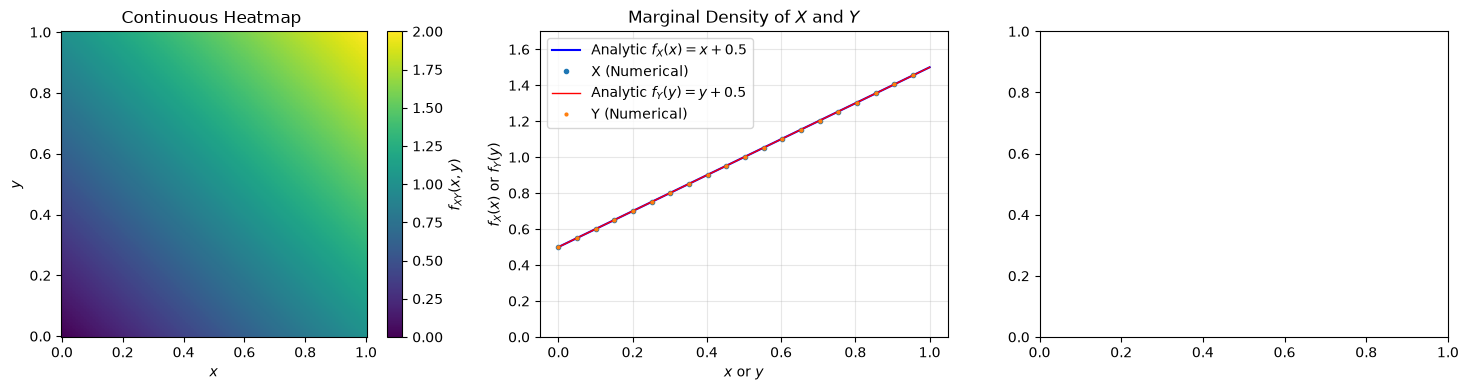

In [ ]:
# grid for x and y
grid = np.linspace(0, 1, 200)
X, Y = np.meshgrid(grid, grid, indexing='ij')

# joint pdf
F_xy = X + Y

# numerical marginals using np.trapezoid
f_x_num = np.trapezoid(F_xy, grid, axis=1)
f_y_num = np.trapezoid(F_xy, grid, axis=0)

# analytic marginals
f_x_analytic = grid + 0.5
f_y_analytic = grid + 0.5

# fig 1 being made
fig1, axes = plt.subplots(1, 3, figsize=(15, 4))

hm = axes[0].pcolormesh(X, Y, Z, cmap="viridis", shading="auto")

fig1.colorbar(hm, ax=axes[0], label=r"$f_{XY}(x, y)$")
axes[0].set_title("Continuous Heatmap ")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$y$")
axes[0].set_aspect("equal")

# Marginal of X
axes[1].plot(
    grid, f_x_analytic, label='Analytic $f_X(x) = x + 0.5$', linewidth=1.5, color='b'
)
axes[1].plot(
    grid[::10],
    f_x_num[::10],
    'o',
    # color='r',
    label='X (Numerical)',
    markersize=3,
)

# Marginal of Y
axes[1].plot(
    grid, f_y_analytic, label='Analytic $f_Y(y) = y + 0.5$', linewidth=1, color='r'
)
axes[1].plot(
    grid[::10],
    f_y_num[::10],
    'o',
    label='Y (Numerical)',
    markersize=2,
)
axes[1].set_title('Marginal Density of $X$ and $Y$')
axes[1].set_xlabel('$x$ or $y$')
axes[1].set_ylabel('$f_X(x)$ or $f_Y(y)$')
axes[1].set_ylim(0, 1.7)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig1.tight_layout()
plt.close(fig1)

### 3. Derive the conditional density of 𝑌 given 𝑋 = 𝑥. Evaluate it at 𝑥 = 0.3 and plot it. Confirm it integrates to 1.

*Conditional Density of 𝑌 given 𝑋 = 𝑥*

$$ f_{Y|X}(y|x) = \frac{x+y}{x+0.5} $$

___

*At 𝑥 = 0.3:*

$$ f_{Y|X}(y|0.3) = \frac{0.3+y}{0.3+0.5} =  \frac{0.3+y}{0.8} $$

$$ \text{at y=0:} \ \ \ f_{Y|X}(0|0.3) $$

$$ \text{at y=1:} \ \ \ f_{Y|X}(1|0.3) $$

___

*Conditional Density integrating to 1*

$$ \int^1_0 f_{Y|X}(y|0.3) \, dy = \int^1_0 \frac{x+y}{x+0.5} \, dy $$

$$ \int^1_0 \frac{x+y}{x+0.5} \, dy = \frac{1}{0.8} \left[ 0.3y + \frac{y^2}{2}\right]^1_0 = $$

$$\boxed{\frac{1}{0.8}(0.3+\frac{1}{2}) = 1}$$

Integral of f_(Y|X)(y | 0.3):	0.9999999999999999
Estimated error:		1.110e-14
At x=0.3, conditional density does still integrate to 1.


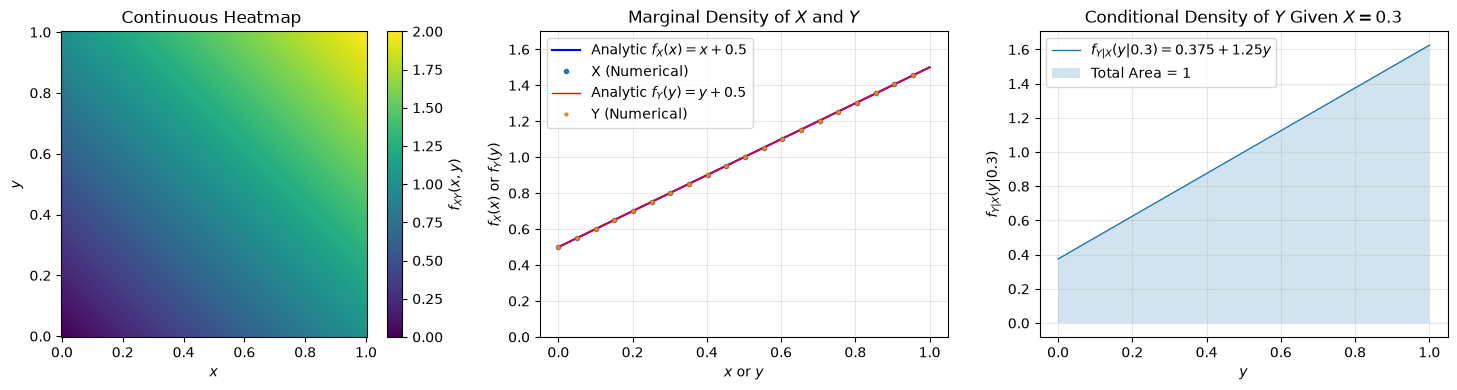

In [76]:
from scipy.integrate import quad

x_val = 0.3
f_y_given_x = lambda y: (x_val + y) / (x_val + 0.5)

area, err = quad(f_y_given_x, 0, 1)

print(f"Integral of f_(Y|X)(y | 0.3):\t{area}\n" + f"Estimated error:\t\t{err:.3e}")
print(f"At x=0.3, conditional density does still integrate to 1.")

# 2. conditional density at x=0.3
y = np.linspace(0, 1, 200)
pdf_vals = f_y_given_x(y)

axes[2].plot(y, pdf_vals, linewidth=1, label=r"$f_{Y|X}(y | 0.3) = 0.375 + 1.25y$", markersize=10)
axes[2].fill_between(y, pdf_vals, alpha=0.2, label="Total Area = 1")
axes[2].set_title("Conditional Density of $Y$ Given $X = 0.3$")
axes[2].set_xlabel("$y$")
axes[2].set_ylabel("$f_{Y|X}(y | 0.3)$")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

fig1

### 4. Compute 𝐸[𝑋], 𝐸[𝑌], 𝐸[𝑋𝑌], Var(𝑋), Cov(𝑋, 𝑌) and the correlation coefficient, all by hand, and verify each by quadrature.

*Computing 𝐸[𝑋] and 𝐸[𝑌]* 

$$
\begin{align*}
E[X] &= \int_0^1 x \left(x + \frac{1}{2}\right) dx \\
     &= \int_0^1 \left(x^2 + \frac{1}{2}x\right) dx \\
     &= \left[ \frac{x^3}{3} + \frac{x^2}{4} \right]_0^1 \\
     &= \frac{1}{3} + \frac{1}{4} = \boxed{\frac{7}{12} = 0.583}
\end{align*} \\
\text{Due to symmetry: }\ \boxed{E[Y] = \frac{7}{12} = 0.583}
$$

___

*Computing 𝐸[𝑋𝑌]*

$$
\begin{align*}
E[XY] &= \int_0^1 \int_0^1 xy(x + y) \, dx \, dy \\
      &= \int_0^1 \left[ \frac{x^3}{3}y + \frac{x^2}{2}y^2 \right]_{x=0}^{x=1} dy \\
      &= \int_0^1 \left( \frac{1}{3}y + \frac{1}{2}y^2 \right) dy \\
      &= \left[ \frac{y^2}{6} + \frac{y^3}{6} \right]_0^1 \\
      &= \boxed{\frac{1}{6} + \frac{1}{6} = \frac{1}{3} = 0.333}
\end{align*}
$$

___

*Computing Var(𝑋)*

$$
\begin{align*}
E[X^2] &= \int_0^1 x^2 \left(x + \frac{1}{2}\right) dx \\
       &= \left[ \frac{x^4}{4} + \frac{x^3}{6} \right]_0^1 \\ 
       &= \frac{1}{4} + \frac{1}{6} = \frac{5}{12}
\end{align*}
\\
\\
\begin{align*}
Var(X) &= E[X^2] - (E[X])^2 \\
&= \frac{5}{12} - \left(\frac{7}{12}\right)^2 \\
&= \frac{60 - 49}{144} \\
&= \boxed{\frac{11}{144}}
\end{align*}
$$

___

*Computing Cov(𝑋, 𝑌)*

$$
\begin{align*}
Cov(X, Y) &= E[XY] - E[X]E[Y] \\
          &= \frac{1}{3} - \left(\frac{7}{12}\right)\left(\frac{7}{12}\right) \\
          &= \boxed{\frac{48 - 49}{144} = -\frac{1}{144}}
\end{align*}
$$

In [88]:
def f_xy(y, x):
  return x + y

#exact values
ex = 7/12
ey = 7/12
exy = 1/3
varx = 11/144
covxy = -1/144

EX, _ = dblquad(lambda y, x: x * f_xy(y, x), 0, 1, 0, 1)
EY, _ = dblquad(lambda y, x: y * f_xy(y, x), 0, 1, 0, 1)
EXY, _ = dblquad(lambda y, x: x * y * f_xy(y, x), 0, 1, 0, 1)
EX2, _ = dblquad(lambda y, x: (x**2) * f_xy(y, x), 0, 1, 0, 1)
EY2, _ = dblquad(lambda y, x: (y**2) * f_xy(y, x), 0, 1, 0, 1)

VarX = EX2 - EX**2
CovXY = EXY - EX * EY

print(f"E[X]      = {EX:.6f}\t | Exact: {ex:.6f}\t | %Error: {(abs(EX-ex)/ex)*100:.6e}")
print(f"E[Y]      = {EY:.6f}\t | Exact: {ey:.6f}\t | %Error: {(abs(EY-ey)/ey)*100:.6e}")
print(f"E[XY]     = {EXY:.6f}\t | Exact: {exy:.6f}\t | %Error: {(abs(EXY-exy)/exy)*100:.6e}")
print(f"Var(X)    = {VarX:.6f}\t | Exact: {varx:.6f}\t | %Error: {(abs(VarX-varx)/varx)*100:.6e}")
print(f"Cov(X, Y) = {CovXY:.6f}\t | Exact: {corxy:.6f}\t | %Error: {(abs(CovXY-covxy)/covxy)*100:.6e}")

E[X]      = 0.583333	 | Exact: 0.583333	 | %Error: 1.903239e-14
E[Y]      = 0.583333	 | Exact: 0.583333	 | %Error: 1.903239e-14
E[XY]     = 0.333333	 | Exact: 0.333333	 | %Error: 3.330669e-14
Var(X)    = 0.076389	 | Exact: 0.076389	 | %Error: 7.266914e-14
Cov(X, Y) = -0.006944	 | Exact: -0.006944	 | %Error: -2.747802e-12


### 5. Generate 10<sup>6</sup> samples from this joint density by rejection sampling, and confirm your sample statistics against the analytic values with standard errors. State your acceptance rate and explain how you chose the bounding constant.

### 6. The correlation is small and negative. Explain in two sentences what in the shape of this density makes 𝑋 and 𝑌 pull against each other.

## Step 2

## Step 3

## Step 4

## Step 5

## Step 6

## Step 7

## Step 8

## Bonus A

## Bonus B

In [ ]:
_end_time = time.perf_counter()
print(f"Total Notebook Runtime: {_end_time - _start_time:.3f} seconds")